# EDA — Violence Detection Dataset (Roboflow `violence-bblcr` v2)

Dataset: https://app.roboflow.com/nguyen-minh-hieu-ev5ll/violence-bblcr/2

Định dạng YOLO detection (2 lớp: Violence / NonViolence), 3 split train/valid/test.
Notebook này khảo sát: số lượng ảnh/nhãn theo split, cân bằng lớp, thống kê bounding box,
độ phân giải ảnh, và ảnh minh hoạ kèm box — dùng cho phần Dataset của báo cáo.

**Chạy trên Google Colab.** Trước khi Run All: bấm icon chìa khoá 🔑 ở thanh bên trái →
thêm secret `ROBOFLOW_API_KEY` → bật toggle "Notebook access". Nếu bỏ qua, notebook sẽ hỏi
nhập key trực tiếp (ẩn ký tự) ở bước tải dataset.

## 1. Cài đặt & cấu hình

In [ ]:
!pip install -q roboflow

import os, glob, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import yaml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.6/324.6 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 56.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.3 MB/s eta 0:00:00


In [ ]:
CFG = {
    "workspace": "nguyen-minh-hieu-ev5ll",
    "project":   "violence-bblcr",
    "version":   2,
    "use_drive": False,   # True -> luu dataset & output vao Google Drive, giu qua cac session
    "drive_dir": "/content/drive/MyDrive/violence-bblcr-eda",
    "raw_dir":   "/content/violence_raw",
    "out_dir":   "/content/eda_out",
    "splits":    ["train", "valid", "test"],
    "res_sample":   300,   # so anh moi split de do do phan giai
    "sample_per_class": 6, # so anh minh hoa moi lop
}

if CFG["use_drive"]:
    from google.colab import drive
    drive.mount("/content/drive")
    CFG["raw_dir"] = f"{CFG['drive_dir']}/violence_raw"
    CFG["out_dir"] = f"{CFG['drive_dir']}/eda_out"

os.makedirs(CFG["out_dir"], exist_ok=True)
print(json.dumps(CFG, indent=2, ensure_ascii=False))

{
  "workspace": "nguyen-minh-hieu-ev5ll",
  "project": "violence-bblcr",
  "version": 2,
  "use_drive": false,
  "drive_dir": "/content/drive/MyDrive/violence-bblcr-eda",
  "raw_dir": "/content/violence_raw",
  "out_dir": "/content/eda_out",
  "splits": [
    "train",
    "valid",
    "test"
  ],
  "res_sample": 300,
  "sample_per_class": 6
}


## 2. Tải dataset từ Roboflow

Ưu tiên đọc `ROBOFLOW_API_KEY` từ Colab Secrets; nếu chưa bật, notebook hỏi nhập key trực tiếp.

In [ ]:
def get_secret(name):
    try:
        from google.colab import userdata
        val = userdata.get(name)
        if val:
            return val
    except Exception:
        pass
    from getpass import getpass
    return getpass(f"{name}: ")


raw = Path(CFG["raw_dir"])

if (raw / "data.yaml").exists():
    print("Da co san dataset tai", raw)
else:
    api_key = get_secret("ROBOFLOW_API_KEY")
    assert api_key, "Thieu ROBOFLOW_API_KEY"
    from roboflow import Roboflow
    rf = Roboflow(api_key=api_key)
    version = (rf.workspace(CFG["workspace"])
                 .project(CFG["project"])
                 .version(CFG["version"]))
    version.download("yolov8", location=str(raw), overwrite=True)

dcfg = yaml.safe_load((raw / "data.yaml").read_text())
NAMES = dcfg["names"] if isinstance(dcfg["names"], list) else [dcfg["names"][i] for i in sorted(dcfg["names"])]
NC = len(NAMES)
VIOLENCE_ID = next(i for i, n in enumerate(NAMES) if "violence" in n.lower() and "non" not in n.lower())

print("Classes:", NAMES, "| Violence id =", VIOLENCE_ID)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/violence_raw in yolov8:: 100%|██████████| 56521/56521 [00:10<00:00, 5165.08it/s]


Classes: ['non-violence', 'violence'] | Violence id = 1


## 3. Số lượng ảnh & nhãn theo split

In [ ]:
def list_images(split):
    return sorted(glob.glob(str(raw / split / "images" / "*")))

def list_labels(split):
    return sorted(glob.glob(str(raw / split / "labels" / "*.txt")))


split_stats = pd.DataFrame([
    {"split": s, "images": len(list_images(s)), "labels": len(list_labels(s))}
    for s in CFG["splits"]
]).set_index("split")
split_stats.loc["total"] = split_stats.sum()
split_stats["pct_images"] = (split_stats["images"] / split_stats.loc["total", "images"] * 100).round(1)
split_stats

,images,labels,pct_images
split,,,
train,26013,26013,92.1
valid,1497,1497,5.3
test,748,748,2.6
total,28258,28258,100.0


## 4. Gom toàn bộ annotation thành DataFrame

In [ ]:
def parse_labels(split):
    rows = []
    for lp in list_labels(split):
        img = Path(lp).stem
        with open(lp) as f:
            lines = [l.split() for l in f if l.strip()]
        if not lines:
            rows.append({"split": split, "image": img, "class_id": -1, "class_name": "empty",
                        "w": np.nan, "h": np.nan, "area": np.nan})
            continue
        for p in lines:
            cid = int(float(p[0]))
            xc, yc, w, h = map(float, p[1:5])
            rows.append({"split": split, "image": img, "class_id": cid, "class_name": NAMES[cid],
                        "x_center": xc, "y_center": yc, "w": w, "h": h,
                        "aspect_ratio": w / h if h else np.nan, "area": w * h})
    return rows


ann = pd.DataFrame([r for s in CFG["splits"] for r in parse_labels(s)])
print(f"{len(ann)} dong annotation ({(ann.class_id == -1).sum()} anh khong co box)")
ann.head()

102515 dong annotation (0 anh khong co box)


,split,image,class_id,class_name,x_center,y_center,w,h,aspect_ratio,area
0,train,-_-_mp4-0_jpg.rf.17e22fbc1e66bfaacb306119a63b9291,0,non-violence,0.189453,0.720703,0.146484,0.123047,1.190476,0.018024
1,train,-_-_mp4-0_jpg.rf.17e22fbc1e66bfaacb306119a63b9291,1,violence,0.253906,0.449219,0.111328,0.179688,0.619565,0.020004
2,train,-_-_mp4-0_jpg.rf.17e22fbc1e66bfaacb306119a63b9291,0,non-violence,0.304688,0.455078,0.087891,0.121094,0.725806,0.010643
3,train,-_-_mp4-0_jpg.rf.17e22fbc1e66bfaacb306119a63b9291,0,non-violence,0.349609,0.341797,0.039062,0.095703,0.408163,0.003738
4,train,-_-_mp4-0_jpg.rf.17e22fbc1e66bfaacb306119a63b9291,0,non-violence,0.302734,0.337891,0.033203,0.097656,0.340000,0.003242


## 5. Cân bằng lớp (theo số box)

class_name  non-violence  violence  ratio_NV:V
split                                         
train              64184     28934        2.22
valid               4438      1813        2.45
test                2296       850        2.70


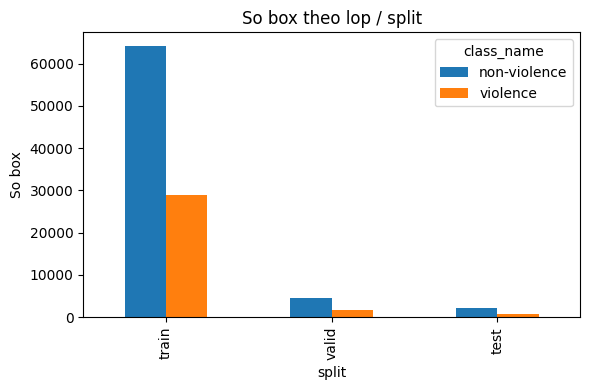

In [ ]:
box_counts = (ann[ann.class_id >= 0]
              .groupby(["split", "class_name"]).size()
              .unstack(fill_value=0)
              .reindex(CFG["splits"]))
box_counts["ratio_NV:V"] = (box_counts.iloc[:, 0] / box_counts.iloc[:, 1]).round(2)
print(box_counts)

box_counts.iloc[:, :2].plot(kind="bar", figsize=(6, 4), title="So box theo lop / split")
plt.ylabel("So box"); plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/class_balance_boxes.png"); plt.show()

## 6. Nhãn theo ảnh (image-level)

Ảnh được gán nhãn Violence nếu có ít nhất 1 box Violence, đồng bộ quy tắc với các notebook đánh giá.

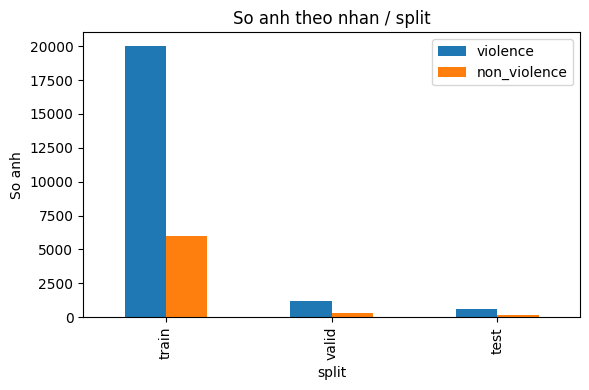

In [ ]:
def image_labels(split):
    g = ann[(ann.split == split) & (ann.class_id >= 0)].groupby("image")["class_id"]
    has_v = g.apply(lambda s: int((s == VIOLENCE_ID).any()))
    empty = set(ann[(ann.split == split) & (ann.class_id == -1)]["image"])
    return has_v, empty


img_stats = []
for s in CFG["splits"]:
    has_v, empty = image_labels(s)
    img_stats.append({"split": s, "violence": int(has_v.sum()), "non_violence": int((has_v == 0).sum()),
                      "empty_label": len(empty)})
img_level = pd.DataFrame(img_stats).set_index("split")
img_level.loc["total"] = img_level.sum()
img_level

img_level.loc[CFG["splits"], ["violence", "non_violence"]].plot(kind="bar", figsize=(6, 4),
    title="So anh theo nhan / split")
plt.ylabel("So anh"); plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/class_balance_images.png"); plt.show()

## 7. Thống kê kích thước bounding box (chuẩn hoá theo ảnh)

class_name          non-violence      violence
w            count  70918.000000  31597.000000
             mean       0.125132      0.202728
             std        0.088720      0.113753
             min        0.001953      0.001953
             25%        0.039062      0.109375
             50%        0.121094      0.195312
             75%        0.187500      0.279297
             max        0.607422      0.736328
h            count  70918.000000  31597.000000
             mean       0.317539      0.426604
             std        0.227197      0.231380
             min        0.001953      0.005859
             25%        0.099609      0.220703
             50%        0.259766      0.378906
             75%        0.539062      0.628906
             max        1.000000      1.000000
area         count  70918.000000  31597.000000
             mean       0.055917      0.106643
             std        0.062347      0.094975
             min        0.000004      0.000011
             

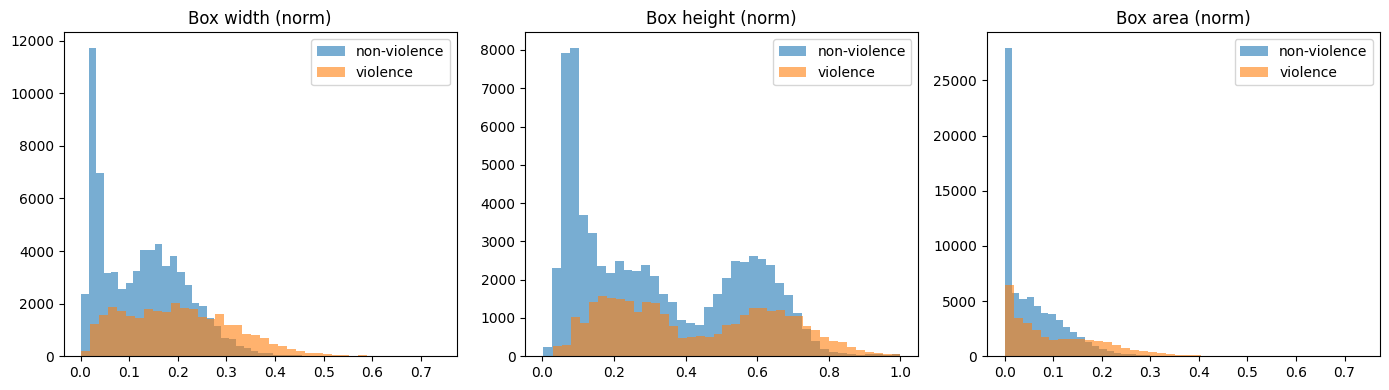

In [ ]:
box_df = ann[ann.class_id >= 0]
print(box_df.groupby("class_name")[["w", "h", "area", "aspect_ratio"]].describe().T)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for cname, sub in box_df.groupby("class_name"):
    axes[0].hist(sub["w"], bins=40, alpha=.6, label=cname)
    axes[1].hist(sub["h"], bins=40, alpha=.6, label=cname)
    axes[2].hist(sub["area"], bins=40, alpha=.6, label=cname)
for ax, t in zip(axes, ["Box width (norm)", "Box height (norm)", "Box area (norm)"]):
    ax.set_title(t); ax.legend()
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/box_size_hist.png"); plt.show()

## 8. Số box mỗi ảnh

         count      mean       std  min  25%  50%  75%   max
split                                                       
test     748.0  4.205882  2.231662  1.0  3.0  4.0  5.0  12.0
train  26013.0  3.579672  1.987390  1.0  2.0  3.0  4.0  11.0
valid   1497.0  4.175685  2.090978  1.0  3.0  4.0  5.0  10.0


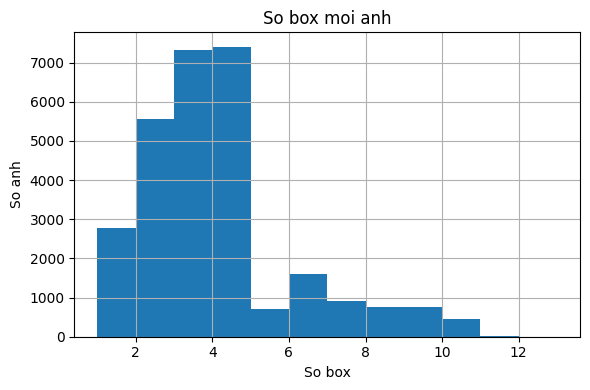

In [ ]:
boxes_per_img = box_df.groupby(["split", "image"]).size()
print(boxes_per_img.groupby("split").describe())

boxes_per_img.hist(bins=range(1, boxes_per_img.max() + 2), figsize=(6, 4))
plt.title("So box moi anh"); plt.xlabel("So box"); plt.ylabel("So anh")
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/boxes_per_image.png"); plt.show()

## 9. Độ phân giải ảnh (mẫu ngẫu nhiên)

split                test  train  valid
width        count  300.0  300.0  300.0
             mean   512.0  512.0  512.0
             std      0.0    0.0    0.0
             min    512.0  512.0  512.0
             25%    512.0  512.0  512.0
             50%    512.0  512.0  512.0
             75%    512.0  512.0  512.0
             max    512.0  512.0  512.0
height       count  300.0  300.0  300.0
             mean   512.0  512.0  512.0
             std      0.0    0.0    0.0
             min    512.0  512.0  512.0
             25%    512.0  512.0  512.0
             50%    512.0  512.0  512.0
             75%    512.0  512.0  512.0
             max    512.0  512.0  512.0
aspect_ratio count  300.0  300.0  300.0
             mean     1.0    1.0    1.0
             std      0.0    0.0    0.0
             min      1.0    1.0    1.0
             25%      1.0    1.0    1.0
             50%      1.0    1.0    1.0
             75%      1.0    1.0    1.0
             max      1.0    1.0    1.0


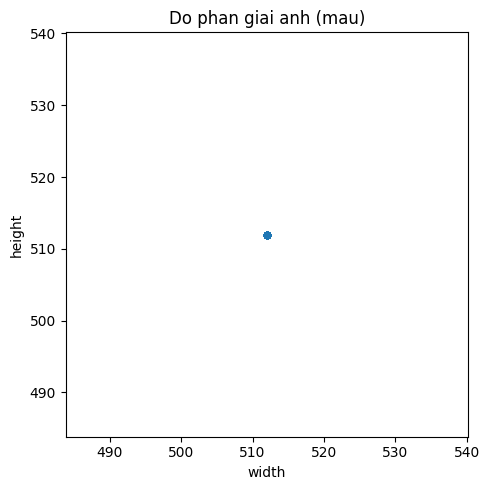

In [ ]:
rng = np.random.default_rng(0)

def sample_resolutions(split, n):
    paths = list_images(split)
    paths = rng.choice(paths, size=min(n, len(paths)), replace=False)
    rows = []
    for p in paths:
        img = cv2.imread(p)
        if img is None:
            continue
        h, w = img.shape[:2]
        rows.append({"split": split, "width": w, "height": h, "aspect_ratio": round(w / h, 3)})
    return rows


res_df = pd.DataFrame([r for s in CFG["splits"] for r in sample_resolutions(s, CFG["res_sample"])])
print(res_df.groupby("split")[["width", "height", "aspect_ratio"]].describe().T)
print("\nSo cap (width, height) khac nhau:", res_df[["width", "height"]].drop_duplicates().shape[0])

res_df.plot.scatter(x="width", y="height", alpha=.3, figsize=(5, 5), title="Do phan giai anh (mau)")
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/resolution_scatter.png"); plt.show()

## 10. Ảnh minh hoạ kèm box

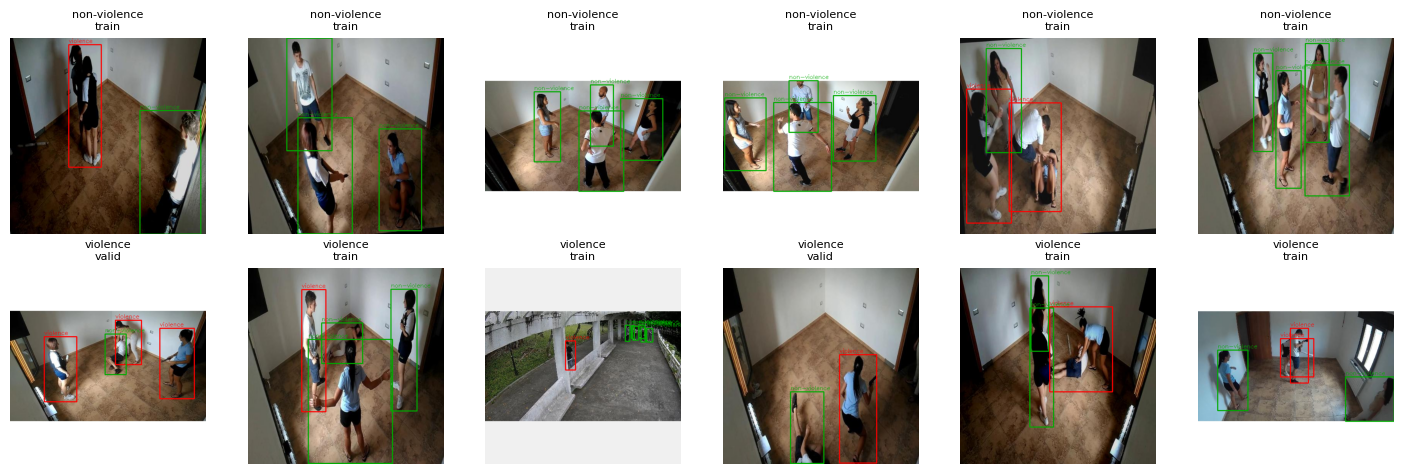

In [ ]:
def draw_boxes(img_path, label_path):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    if os.path.exists(label_path):
        for line in open(label_path):
            p = line.split()
            if len(p) < 5:
                continue
            cid = int(float(p[0]))
            xc, yc, bw, bh = [float(x) for x in p[1:5]]
            x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
            x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
            color = (255, 0, 0) if cid == VIOLENCE_ID else (0, 170, 0)
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            cv2.putText(img, NAMES[cid], (x1, max(0, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, .5, color, 1)
    return img


samples = []
for cname, cid in [(n, i) for i, n in enumerate(NAMES)]:
    # Filter box_df for the current class name to get relevant images and their splits
    class_images_info = box_df[box_df.class_name == cname][['split', 'image']].drop_duplicates()

    if not class_images_info.empty:
        # Convert to a list of (split, image) tuples for rng.choice
        unique_image_tuples = list(class_images_info.itertuples(index=False, name=None))

        # Sample these tuples
        sampled_image_tuples = rng.choice(
            unique_image_tuples,
            size=min(CFG["sample_per_class"], len(unique_image_tuples)),
            replace=False
        )

        for split_val, img_name in sampled_image_tuples:
            samples.append((split_val, img_name, cname))

n = len(samples)
cols = CFG["sample_per_class"]
fig, axes = plt.subplots(NC, cols, figsize=(cols * 2.4, NC * 2.4))
for ax in axes.ravel():
    ax.axis("off")
for k, (split, img, cname) in enumerate(samples):
    row_i, col_i = divmod(k, cols)
    ip = str(raw / split / "images" / f"{img}.jpg")
    if not os.path.exists(ip):
        ip = glob.glob(str(raw / split / "images" / f"{img}.*"))[0]
    lp = str(raw / split / "labels" / f"{img}.txt")
    axes[row_i, col_i].imshow(draw_boxes(ip, lp))
    axes[row_i, col_i].set_title(f"{cname}\n{split}", fontsize=8)
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/sample_grid.png", dpi=120); plt.show()


## 11. Tổng kết

In [ ]:
summary = {
    "dataset": f"{CFG['workspace']}/{CFG['project']} v{CFG['version']}",
    "classes": NAMES,
    "images_per_split": split_stats["images"].drop("total").to_dict(),
    "empty_label_images_per_split": img_level["empty_label"].drop("total").to_dict(),
    "image_level_balance_per_split": img_level[["violence", "non_violence"]].drop("total").to_dict("index"),
    "box_level_balance_per_split": box_counts.iloc[:, :2].to_dict("index"),
    "boxes_per_image": {"mean": float(boxes_per_img.mean()), "max": int(boxes_per_img.max())},
    "box_area_norm": {"mean": float(box_df.area.mean()), "median": float(box_df.area.median())},
    "resolution_sample": {"n": len(res_df), "unique_sizes": int(res_df[["width", "height"]].drop_duplicates().shape[0])},
}
with open(f"{CFG['out_dir']}/eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "dataset": "nguyen-minh-hieu-ev5ll/violence-bblcr v2",
  "classes": [
    "non-violence",
    "violence"
  ],
  "images_per_split": {
    "train": 26013,
    "valid": 1497,
    "test": 748
  },
  "empty_label_images_per_split": {
    "train": 0,
    "valid": 0,
    "test": 0
  },
  "image_level_balance_per_split": {
    "train": {
      "violence": 20025,
      "non_violence": 5988
    },
    "valid": {
      "violence": 1176,
      "non_violence": 321
    },
    "test": {
      "violence": 577,
      "non_violence": 171
    }
  },
  "box_level_balance_per_split": {
    "train": {
      "non-violence": 64184,
      "violence": 28934
    },
    "valid": {
      "non-violence": 4438,
      "violence": 1813
    },
    "test": {
      "non-violence": 2296,
      "violence": 850
    }
  },
  "boxes_per_image": {
    "mean": 3.627822209639748,
    "max": 12
  },
  "box_area_norm": {
    "mean": 0.07155160606706898,
    "median": 0.046966552734375
  },
  "resolution_sample": {
    "n": 90

## 12. Kiểm tra chất lượng dữ liệu (Data Quality)

Phần này kiểm tra ảnh không đọc được, nhãn bị thiếu, nhãn không có ảnh tương ứng, sai cấu trúc YOLO, class ID không hợp lệ và tọa độ bounding box bất thường. Các lỗi được ghi nhận để xem xét trước khi huấn luyện.

In [ ]:
from collections import Counter
import hashlib
import math

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
quality_rows = []
hash_rows = []
orphan_label_rows = []

for split in CFG["splits"]:
    image_paths = [Path(x) for x in list_images(split) if Path(x).suffix.lower() in IMAGE_EXTS]
    label_paths = [Path(x) for x in list_labels(split)]
    image_by_stem = {}
    for ip in image_paths:
        image_by_stem.setdefault(ip.stem, []).append(ip)

    labels_by_stem = {lp.stem: lp for lp in label_paths}
    for stem, lp in labels_by_stem.items():
        if stem not in image_by_stem:
            orphan_label_rows.append({"split": split, "label": lp.name, "issue": "label_without_image"})

    for ip in image_paths:
        issues = []
        img = cv2.imread(str(ip))
        if img is None:
            issues.append("unreadable_image")
            width = height = None
            brightness = contrast = sharpness = np.nan
            digest = None
        else:
            height, width = img.shape[:2]
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            brightness = float(gray.mean())
            contrast = float(gray.std())
            sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
            digest = hashlib.md5(ip.read_bytes()).hexdigest()
            hash_rows.append({"split": split, "image": ip.name, "path": str(ip), "md5": digest})

        lp = labels_by_stem.get(ip.stem)
        if lp is None:
            issues.append("missing_label_file")
            label_line_count = 0
        else:
            lines = [line.strip() for line in lp.read_text(encoding="utf-8", errors="replace").splitlines() if line.strip()]
            label_line_count = len(lines)
            for line_no, line in enumerate(lines, start=1):
                parts = line.split()
                if len(parts) != 5:
                    issues.append(f"line_{line_no}_invalid_field_count")
                    continue
                try:
                    cid_float = float(parts[0])
                    coords = [float(v) for v in parts[1:]]
                except ValueError:
                    issues.append(f"line_{line_no}_non_numeric")
                    continue
                if not cid_float.is_integer() or not (0 <= int(cid_float) < NC):
                    issues.append(f"line_{line_no}_invalid_class_id")
                if not all(math.isfinite(v) for v in coords):
                    issues.append(f"line_{line_no}_non_finite_coordinate")
                    continue
                xc, yc, bw, bh = coords
                if not (0 <= xc <= 1 and 0 <= yc <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
                    issues.append(f"line_{line_no}_coordinate_out_of_range")
                if xc - bw / 2 < 0 or yc - bh / 2 < 0 or xc + bw / 2 > 1 or yc + bh / 2 > 1:
                    issues.append(f"line_{line_no}_box_exceeds_image")

        quality_rows.append({
            "split": split, "image": ip.name, "width": width, "height": height,
            "label_lines": label_line_count, "brightness_mean": brightness,
            "contrast_std": contrast, "sharpness_laplacian_var": sharpness,
            "issue_count": len(issues), "issues": "; ".join(sorted(set(issues)))
        })

quality_df = pd.DataFrame(quality_rows)
orphan_labels_df = pd.DataFrame(orphan_label_rows, columns=["split", "label", "issue"])
image_hashes = pd.DataFrame(hash_rows)

quality_summary = quality_df.groupby("split").agg(
    images=("image", "count"),
    images_with_issues=("issue_count", lambda x: int((x > 0).sum())),
    unreadable_images=("issues", lambda x: int(x.str.contains("unreadable_image").sum())),
    missing_label_files=("issues", lambda x: int(x.str.contains("missing_label_file").sum())),
    mean_brightness=("brightness_mean", "mean"),
    mean_contrast=("contrast_std", "mean"),
    mean_sharpness=("sharpness_laplacian_var", "mean")
).round(3)
quality_summary["orphan_label_files"] = orphan_labels_df.groupby("split").size().reindex(quality_summary.index, fill_value=0)
display(quality_summary)
display(quality_df[quality_df.issue_count > 0].head(30))
display(orphan_labels_df.head(30))

quality_df.to_csv(f"{CFG['out_dir']}/data_quality_by_image.csv", index=False)
orphan_labels_df.to_csv(f"{CFG['out_dir']}/orphan_label_files.csv", index=False)


,images,images_with_issues,unreadable_images,missing_label_files,mean_brightness,mean_contrast,mean_sharpness,orphan_label_files
split,,,,,,,,
test,748,0,0,0,145.802,73.621,1574.423,0
train,26013,0,0,0,127.869,65.045,995.167,0
valid,1497,0,0,0,145.791,73.663,1507.198,0


,split,image,width,height,label_lines,brightness_mean,contrast_std,sharpness_laplacian_var,issue_count,issues


,split,label,issue


## 13. Phân bố vị trí bounding box

Biểu đồ tâm box theo trục X/Y giúp quan sát vùng ảnh thường xuất hiện đối tượng. Heatmap được tách theo lớp để kiểm tra khác biệt phân bố không gian giữa Violence và NonViolence.

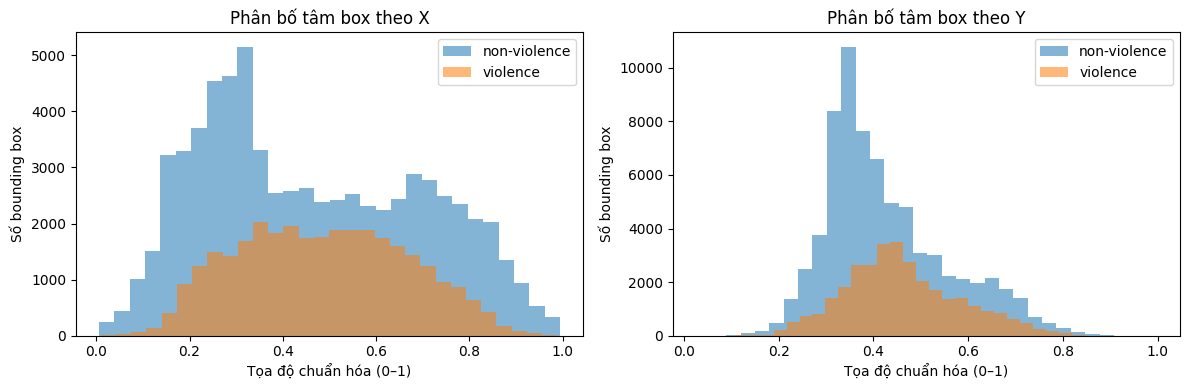

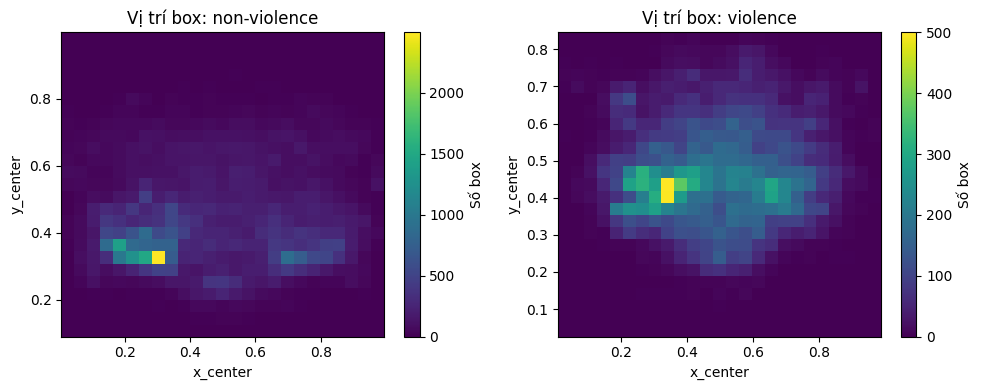

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cname, sub in box_df.groupby("class_name"):
    axes[0].hist(sub["x_center"], bins=30, alpha=.55, label=cname)
    axes[1].hist(sub["y_center"], bins=30, alpha=.55, label=cname)
axes[0].set_title("Phân bố tâm box theo X")
axes[1].set_title("Phân bố tâm box theo Y")
for ax in axes:
    ax.set_xlabel("Tọa độ chuẩn hóa (0–1)")
    ax.set_ylabel("Số bounding box")
    ax.legend()
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/bbox_center_distribution.png", dpi=140)
plt.show()

classes_present = list(box_df["class_name"].dropna().unique())
fig, axes = plt.subplots(1, max(1, len(classes_present)), figsize=(5 * max(1, len(classes_present)), 4), squeeze=False)
for ax, cname in zip(axes.ravel(), classes_present):
    sub = box_df[box_df.class_name == cname]
    h = ax.hist2d(sub["x_center"], sub["y_center"], bins=25)
    ax.set_title(f"Vị trí box: {cname}")
    ax.set_xlabel("x_center")
    ax.set_ylabel("y_center")
    plt.colorbar(h[3], ax=ax, label="Số box")
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/bbox_position_heatmap.png", dpi=140)
plt.show()


## 14. Chất lượng ảnh và kích thước box theo lớp

Brightness là độ sáng trung bình ảnh xám; contrast là độ lệch chuẩn cường độ pixel; sharpness dùng phương sai Laplacian như một chỉ báo độ nét tương đối. Các chỉ số này chỉ mang tính mô tả, không tự động xác định ảnh tốt hay xấu.

brightness_mean                                                      \
                count     mean     std     min      25%      50%      75%   
split                                                                       
test            748.0  145.802  33.112  87.980  104.324  166.676  172.744   
train         26013.0  127.869  36.390  56.146   97.598  119.833  166.382   
valid          1497.0  145.791  32.971  88.670  104.376  166.361  172.686   

               contrast_std          ...                  \
           max        count    mean  ...     75%     max   
split                                ...                   
test   177.813        748.0  73.621  ...  85.665  92.173   
train  200.282      26013.0  65.045  ...  79.119  94.862   
valid  178.917       1497.0  73.663  ...  85.757  93.233   

      sharpness_laplacian_var                                                 \
                        count      mean       std      min      25%      50%   
split                                                                          
test                    748.0  1574.423  1601.358  153.453  377.925  801.501   
train                 26013.0   995.167  1342.343   79.911  228.987  333.178   
valid                  1497.0  1507.198  1548.445  182.527  378.799  824.440   

                           
            75%       max  
split                      
test   3336.932  7297.168  
train   903.031  7448.438  
valid  3275.623  7197.800  

[3 rows x 24 columns]

The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


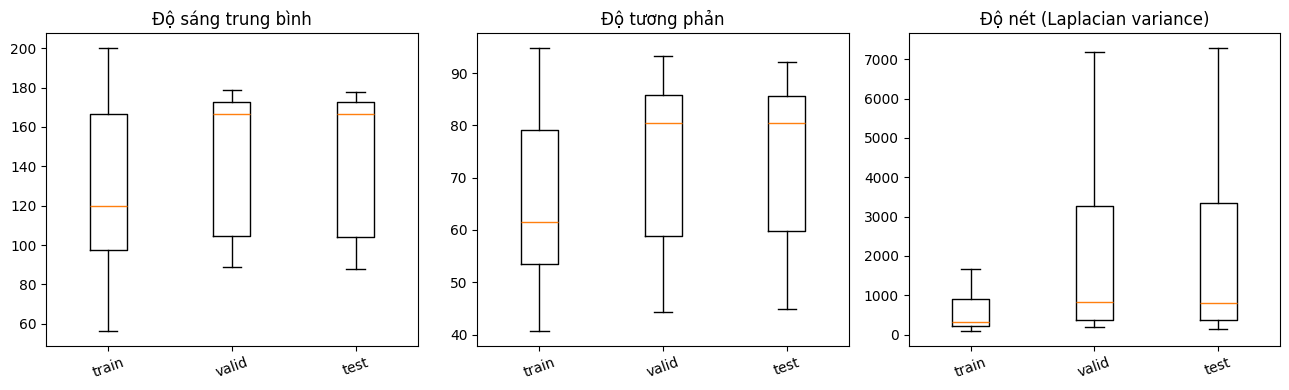

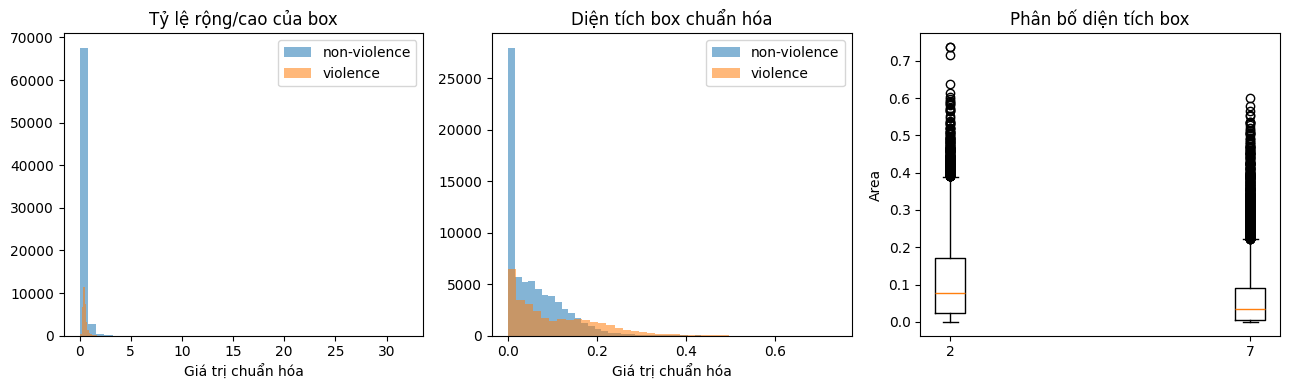

In [ ]:
display(quality_df.groupby("split")[["brightness_mean", "contrast_std", "sharpness_laplacian_var"]].describe().round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
metrics = [
    ("brightness_mean", "Độ sáng trung bình"),
    ("contrast_std", "Độ tương phản"),
    ("sharpness_laplacian_var", "Độ nét (Laplacian variance)")
]
for ax, (col, title) in zip(axes, metrics):
    data = [quality_df.loc[quality_df.split == s, col].dropna().values for s in CFG["splits"]]
    ax.boxplot(data, labels=CFG["splits"], showfliers=False)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/image_quality_by_split.png", dpi=140)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for cname, sub in box_df.groupby("class_name"):
    axes[0].hist(sub["aspect_ratio"].replace([np.inf, -np.inf], np.nan).dropna(), bins=40, alpha=.55, label=cname)
    axes[1].hist(sub["area"], bins=40, alpha=.55, label=cname)
    axes[2].boxplot(sub["area"].dropna(), positions=[len(axes[2].get_xticks()) + 1], widths=.5)
axes[0].set_title("Tỷ lệ rộng/cao của box")
axes[1].set_title("Diện tích box chuẩn hóa")
axes[2].set_title("Phân bố diện tích box")
axes[2].set_ylabel("Area")
for ax in axes[:2]:
    ax.set_xlabel("Giá trị chuẩn hóa")
    ax.legend()
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/bbox_shape_area_by_class.png", dpi=140)
plt.show()


## 15. Trùng lặp ảnh giữa các split

Ảnh có cùng MD5 là các file có nội dung byte giống hệt nhau. Việc phát hiện trùng lặp giữa train/valid/test hữu ích để rà soát nguy cơ rò rỉ dữ liệu; ảnh khác mã hóa nhưng cùng nội dung có thể không được phát hiện bằng MD5.

In [ ]:
duplicate_groups = pd.DataFrame(columns=["md5", "n_images", "splits", "files"])
if not image_hashes.empty:
    duplicate_groups = (image_hashes.groupby("md5")
        .agg(n_images=("image", "size"),
             splits=("split", lambda x: ", ".join(sorted(set(x)))),
             files=("image", lambda x: ", ".join(x)))
        .reset_index())
    duplicate_groups = duplicate_groups[duplicate_groups.n_images > 1].sort_values("n_images", ascending=False)

cross_split_duplicates = duplicate_groups[
    duplicate_groups["splits"].apply(lambda x: len(x.split(", ")) > 1)
].copy()

print("Số nhóm ảnh trùng nội dung:", len(duplicate_groups))
print("Số nhóm trùng xuất hiện ở nhiều split:", len(cross_split_duplicates))
display(cross_split_duplicates.head(30))
duplicate_groups.to_csv(f"{CFG['out_dir']}/duplicate_image_groups.csv", index=False)


Số nhóm ảnh trùng nội dung: 8
Số nhóm trùng xuất hiện ở nhiều split: 0


,md5,n_images,splits,files


## 16. Cập nhật tổng kết EDA

Bổ sung các chỉ số chất lượng dữ liệu, chất lượng ảnh và trùng lặp vào file JSON tổng hợp đã tạo ở phần 11.

In [ ]:
summary.update({
    "data_quality": {
        "images_with_issues_per_split": quality_summary["images_with_issues"].to_dict(),
        "unreadable_images_per_split": quality_summary["unreadable_images"].to_dict(),
        "missing_label_files_per_split": quality_summary["missing_label_files"].to_dict(),
        "orphan_label_files_per_split": quality_summary["orphan_label_files"].to_dict(),
        "cross_split_duplicate_groups": int(len(cross_split_duplicates))
    },
    "image_quality_mean": quality_df.groupby("split")[
        ["brightness_mean", "contrast_std", "sharpness_laplacian_var"]
    ].mean().round(3).to_dict("index"),
    "bbox_position_mean": box_df.groupby("class_name")[
        ["x_center", "y_center"]
    ].mean().round(4).to_dict("index"),
    "bbox_aspect_ratio": {
        "mean": float(box_df["aspect_ratio"].replace([np.inf, -np.inf], np.nan).dropna().mean()),
        "median": float(box_df["aspect_ratio"].replace([np.inf, -np.inf], np.nan).dropna().median())
    }
})
with open(f"{CFG['out_dir']}/eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print(json.dumps(summary, indent=2, ensure_ascii=False))
print("EDA outputs saved to:", CFG["out_dir"])


{
  "dataset": "nguyen-minh-hieu-ev5ll/violence-bblcr v2",
  "classes": [
    "non-violence",
    "violence"
  ],
  "images_per_split": {
    "train": 26013,
    "valid": 1497,
    "test": 748
  },
  "empty_label_images_per_split": {
    "train": 0,
    "valid": 0,
    "test": 0
  },
  "image_level_balance_per_split": {
    "train": {
      "violence": 20025,
      "non_violence": 5988
    },
    "valid": {
      "violence": 1176,
      "non_violence": 321
    },
    "test": {
      "violence": 577,
      "non_violence": 171
    }
  },
  "box_level_balance_per_split": {
    "train": {
      "non-violence": 64184,
      "violence": 28934
    },
    "valid": {
      "non-violence": 4438,
      "violence": 1813
    },
    "test": {
      "non-violence": 2296,
      "violence": 850
    }
  },
  "boxes_per_image": {
    "mean": 3.627822209639748,
    "max": 12
  },
  "box_area_norm": {
    "mean": 0.07155160606706898,
    "median": 0.046966552734375
  },
  "resolution_sample": {
    "n": 90

### 📋 Gợi ý nội dung slide thuyết trình EDA (Dành cho báo cáo/thuyết trình)

Dưới đây là cấu trúc slide được chuẩn hoá dựa trực tiếp trên các kết quả chạy ra từ notebook của bạn:

---

#### Slide 1: Giới thiệu chung về Dataset
*   **Tiêu đề:** Khảo sát & Đánh giá Dữ liệu Phát hiện Bạo lực (Violence Detection - Roboflow `violence-bblcr` v2).
*   **Nội dung:**
    *   Nguồn dữ liệu: Roboflow (28,258 ảnh).
    *   Định dạng: YOLOv8 PyTorch (Bounding Box).
    *   Bài toán: Phân loại đa đối tượng & phát hiện hành vi: **Violence** (Bạo lực) vs **Non-Violence** (Không bạo lực).

#### Slide 2: Phân bố dữ liệu giữa các Split (Train / Valid / Test)
*   **Hình ảnh minh hoạ:** Bảng thống kê số lượng ảnh hoặc biểu đồ số lượng ảnh mỗi split.
*   **Số liệu chính:**
    *   **Train:** 26,013 ảnh (~92.1%)
    *   **Valid:** 1,497 ảnh (~5.3%)
    *   **Test:** 748 ảnh (~2.6%)
    *   *Nhận xét:* Tập huấn luyện chiếm tỷ trọng lớn, đảm bảo mô hình có đủ mẫu học. Tuy nhiên tập Test và Valid hơi nhỏ, cần lưu ý khi đánh giá độ tổng quát hoá.

#### Slide 3: Sự mất cân bằng nhãn (Class Imbalance)
*   **Hình ảnh minh hoạ:** Biểu đồ cột từ phần `5` và `6` (`class_balance_boxes.png` và `class_balance_images.png`).
*   **Nội dung:**
    *   **Mức độ Bounding Box:** Tỷ lệ nhãn Non-Violence gấp khoảng **2.2 đến 2.7 lần** nhãn Violence trên toàn bộ các split (ví dụ ở tập Train: 64k box Non-Violence so với 28k box Violence).
    *   **Mức độ Ảnh (Image-level):** Ngược lại, đa số ảnh đều chứa ít nhất một hành vi bạo lực (Tập train có 20,025 ảnh Violence và chỉ có 5,988 ảnh thuần Non-Violence).
    *   *Giải pháp đề xuất khi Train:* Áp dụng các kỹ thuật cân bằng loss (như Focal Loss) hoặc tăng cường dữ liệu (Data Augmentation) cho lớp thiểu số để tránh thiên vị.

#### Slide 4: Thống kê kích thước & Tỷ lệ khung hình Bounding Box
*   **Hình ảnh minh hoạ:** Biểu đồ histogram phân bố chiều rộng, cao, diện tích (`box_size_hist.png` hoặc `bbox_shape_area_by_class.png`).
*   **Nội dung:**
    *   **Đặc tính:** Các box thuộc lớp `Violence` thường có diện tích lớn hơn (trung bình diện tích chuẩn hóa là **0.106**) so với `Non-Violence` (trung bình **0.055**).
    *   **Tỷ lệ rộng/cao (Aspect Ratio):** Trung vị là **0.39** (dáng người đứng, hẹp chiều ngang và dài chiều dọc).
    *   *Ý nghĩa:* Giúp cấu hình Anchor boxes cho các mô hình Object Detection phù hợp (ưu tiên các box dạng đứng thuôn dài).

#### Slide 5: Phân bố vị trí hành vi (Spatial Distribution Heatmap)
*   **Hình ảnh minh hoạ:** Bản đồ nhiệt vị trí tâm box (`bbox_position_heatmap.png`).
*   **Nội dung:**
    *   Các hành vi bạo lực lẫn không bạo lực tập trung chủ yếu ở **vùng trung tâm phía dưới** của ảnh (y_center khoảng 0.35 - 0.55, x_center từ 0.25 - 0.75).
    *   *Nhận xét:* Dữ liệu phản ánh thực tế camera giám sát (đối tượng đứng trên mặt sàn). Mô hình cần chú ý phân bổ này để tránh học tủ bias vị trí biên ảnh.

#### Slide 6: Kiểm tra chất lượng dữ liệu (Data Quality & Leakage)
*   **Nội dung:**
    *   **Độ phân giải:** Đồng nhất 100% mẫu khảo sát đều đạt kích thước chuẩn **512 x 512** pixel.
    *   **Tính toàn vẹn (Integrity):** Không có ảnh nào bị lỗi không đọc được (`unreadable_image` = 0), không thiếu file nhãn hay nhãn mồ côi.
    *   **Rò rỉ dữ liệu (Data Leakage):** Đã kiểm tra trùng lặp MD5 giữa các tập. **Không phát hiện** bất kỳ ảnh nào bị lặp chéo giữa Train ↔ Valid hay Train ↔ Test. Đây là điểm cộng cực kỳ lớn đảm bảo kết quả đánh giá mô hình là khách quan và đáng tin cậy.

#### Slide 7: Ảnh minh hoạ trực quan (Sample Grid)
*   **Hình ảnh minh hoạ:** Lưới ảnh mẫu trực quan hoá bounding box (`sample_grid.png`).
*   **Nội dung:**
    *   Show trực quan một số ca bạo lực (khung đỏ) và không bạo lực (khung xanh).
    *   *Nhận xét trực quan:* Bối cảnh chủ yếu trong phòng, không gian hẹp (khá giống góc quay camera an ninh trong nhà/lớp học).

### 💡 Các phát hiện quan trọng (EDA Insights) giúp bài thuyết trình nổi bật

Khi thuyết trình, thay vì chỉ đọc các con số khô khan, bạn hãy đưa các phân tích mang tính **định hướng giải pháp huấn luyện** dưới đây vào slide để ghi điểm tối đa:

#### 1. Sự bất đối xứng thú vị giữa mức độ Box và mức độ Ảnh
*   **Vấn đề:** Ở mức độ bounding box, `non-violence` nhiều gấp **2.2 đến 2.7 lần** `violence`. Nhưng ở mức độ ảnh, hơn **70% số ảnh** chứa ít nhất một box `violence`.
*   **Giải thích thực tế:** Trong một khung cảnh bạo lực (ví dụ: xô xát, đánh nhau), thường chỉ có 1 hoặc 2 tác nhân trực tiếp hành hung (nhãn `violence`), còn lại là nhiều người xung quanh đứng xem hoặc can ngăn (nhãn `non-violence`).
*   **Lưu ý cho Mô hình:** Mô hình YOLO của bạn sẽ học rất tốt các đối tượng người bình thường (`non-violence`), nhưng có nguy cơ bị sót hoặc nhận diện sai hành vi bạo lực (`violence`) do số lượng box của lớp này ít hơn hẳn. Bạn nên đề xuất sử dụng **Augmentation chọn lọc (chỉ xoay/ghép các ảnh chứa box Violence)** khi train.

#### 2. Kích thước vật lý của hành vi bạo lực
*   **Vấn đề:** Diện tích trung bình của box bạo lực (**0.106**) lớn gần gấp đôi box không bạo lực (**0.055**).
*   **Giải thích thực tế:** Hành vi bạo lực (đánh, đấm, giằng co) thường yêu cầu các hành động vung tay chân, xô đẩy, ép sát lẫn nhau, vô tình gộp các đối tượng lại thành một vùng hoạt động lớn hơn trên camera. Ngược lại, người không bạo lực thường đứng riêng lẻ hoặc có tư thế khép kín nên box nhỏ gọn hơn.
*   **Lưu ý cho Mô hình:** Mô hình rất dễ nhận diện nhầm các vật thể/người đứng sát nhau thành hành vi bạo lực chỉ vì chúng tạo ra một bounding box lớn. Cần chuẩn bị các ca kiểm thử (Test Cases) có người đứng sát nhau nói chuyện bình thường để kiểm tra độ nhạy của mô hình.

#### 3. Phân bố không gian tập trung và bài toán góc chết camera
*   **Vấn đề:** Cả 2 lớp tập trung cao độ ở trục Y từ **0.35 đến 0.55** (vùng trung tâm dốc xuống sàn).
*   **Giải thích thực tế:** Toàn bộ ảnh được quay từ góc camera an ninh gắn tường (high-angle camera) nhìn xuống phòng. Đối tượng luôn đứng trên sàn nhà, tạo ra một khoảng trống lớn ở phần trần nhà (phía trên ảnh).
*   **Lưu ý cho Mô hình:** Mô hình có thể bị "lười" và bỏ qua việc quét kỹ các vùng biên hoặc góc cao của ảnh. Nếu áp dụng mô hình này vào camera có góc quay cực thấp (low-angle) hoặc đặt ngang tầm mắt, độ chính xác có thể giảm sút nghiêm trọng. Đây chính là phần **Hạn chế của bộ dữ liệu (Dataset Limitations)** mà các thầy cô trong hội đồng rất thích nghe bạn tự nhận thức được.

#### 4. Thử thách về Độ phân giải cố định (512x512)
*   **Vấn đề:** 100% ảnh đạt kích thước đồng nhất **512x512**.
*   **Ưu điểm:** Tiết kiệm thời gian tiền xử lý ảnh khi huấn luyện.
*   **Thử thách:** Khi triển khai thực tế trên các camera giám sát FullHD (1920x1080) hoặc 4K, luồng video sẽ phải nén luồng hình ảnh về dạng vuông (Square resize). Việc này có thể làm méo tỷ lệ cơ thể người (Aspect Ratio), ảnh hưởng đến khả năng phát hiện dáng người đứng của YOLO. Bạn nên đề xuất giải pháp **Letterbox Resize** (thêm viền đen thay vì bóp méo ảnh) khi triển khai thực tế.